In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## Load and prepare MNIST data

100.0%
100.0%
100.0%
100.0%


Training examples:   54,000
Validation examples: 6,000
Test examples:       10,000


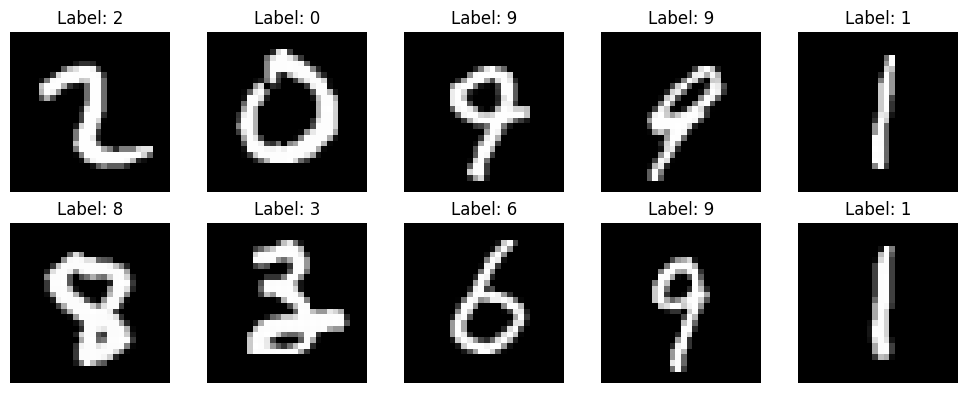

In [ ]:
## Define how to transform and normalize the images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

## Load MNIST dataset 
full_train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

## Split training data 
train_size = 54_000
val_size = len(full_train_dataset) - train_size
split_generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size], generator=split_generator
)

##Create batches 
BATCH_SIZE = 128

## Create dataloaders to load batches
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Print the number of images in each dataset
print(f"Training examples:   {len(train_dataset):,}")
print(f"Validation examples: {len(val_dataset):,}")
print(f"Test examples:       {len(test_dataset):,}")

## Display sample images for confirmation
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    # Undo normalization for display
    shown = image.squeeze().numpy() * 0.3081 + 0.1307
    ax.imshow(shown, cmap="gray")
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()


## Implement CNN model

In [ ]:
class MNIST_CNN(nn.Module):
    def __init__(self, dropout_rate=0.25): ##Initialize the CNN 
        super().__init__() ##Initialze the parent nn.Module class
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1) ##First convolutional layer
        self.relu1 = nn.ReLU() ##Introduce nonlineraity into the network
        self.pool1 = nn.MaxPool2d(2)  ##Reduce size of the feature maps     

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) ##Second convolutional layer
        self.relu2 = nn.ReLU() ##Introduce nonlineraity into the network
        self.pool2 = nn.MaxPool2d(2)  ##Reduce size of the feature maps     

        self.dropout = nn.Dropout(dropout_rate) ## Dropout rate is 0.25
        self.fc1 = nn.Linear(64 * 7 * 7, 128) ## First fully connected layer
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10) ##Final fully connecetd layer

    def forward(self, x): #Define the order that layers process images
        x = self.pool1(self.relu1(self.conv1(x))) ## 1st Convolution, ReLu activation, Max pooling
        x = self.pool2(self.relu2(self.conv2(x))) ## 2nd convolution, RELu activation, Max pooling
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.relu3(self.fc1(x)))
        return self.fc2(x)

model = MNIST_CNN(dropout_rate=0.25).to(DEVICE) ##Create CNN model
print(model) ## Confirm model created
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


MNIST_CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 421,642


## Visulize training configuration and early stopping

In [ ]:
## Training hyperparameters
LEARNING_RATE = 0.001
MAX_EPOCHS = 15
PATIENCE = 4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss() ## Loss function

## Define Adam optimizer to adjust weights 
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

# Training and evaulating modes. If optimizer is true it's training, if false it's evaluating
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0 ## Initialize tracking variables

    ## Control gradient calculations 
    with torch.set_grad_enabled(training):
        for x, y in loader: ## Process batches 
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad() ## clear prvious gradients 

            logits = model(x) ## Forward propagation
            loss = criterion(logits, y) ## Calculate the loss

            if training:
                loss.backward() ## Back propagation
                optimizer.step() ## Weights are updated

            total_loss += loss.item() * x.size(0) ##Loss and accuracy are tracked 
            correct += (logits.argmax(dim=1) == y).sum().item() ## Count number of correct predictions
            total += y.size(0) ## Add correct number to total correct 

    return total_loss / total, correct / total ## Return results

## Create history dictionary to store performance after each epoch 
history = {
    "train_loss": [], "val_loss": [],
    "train_accuracy": [], "val_accuracy": []
}
best_val_loss = float("inf") ## Track the best model 
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1): ## Training loop 
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion)

    ## Record results 
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    ## Print training results 
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_loss:.4f}, acc {train_acc:.4f} | "
        f"val loss {val_loss:.4f}, acc {val_acc:.4f}"
    )

    ## Early stopping checks
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

model.load_state_dict(best_state)
print(f"Restored checkpoint with validation loss: {best_val_loss:.4f}")


Epoch 01/15 | train loss 0.2103, acc 0.9356 | val loss 0.0612, acc 0.9833
Epoch 02/15 | train loss 0.0606, acc 0.9813 | val loss 0.0481, acc 0.9857
Epoch 03/15 | train loss 0.0439, acc 0.9867 | val loss 0.0423, acc 0.9882
Epoch 04/15 | train loss 0.0355, acc 0.9893 | val loss 0.0425, acc 0.9870
Epoch 05/15 | train loss 0.0298, acc 0.9906 | val loss 0.0394, acc 0.9885
Epoch 06/15 | train loss 0.0252, acc 0.9918 | val loss 0.0389, acc 0.9887
Epoch 07/15 | train loss 0.0220, acc 0.9928 | val loss 0.0407, acc 0.9885
Epoch 08/15 | train loss 0.0200, acc 0.9935 | val loss 0.0368, acc 0.9890
Epoch 09/15 | train loss 0.0185, acc 0.9937 | val loss 0.0387, acc 0.9898
Epoch 10/15 | train loss 0.0165, acc 0.9947 | val loss 0.0350, acc 0.9912
Epoch 11/15 | train loss 0.0156, acc 0.9949 | val loss 0.0329, acc 0.9907
Epoch 12/15 | train loss 0.0150, acc 0.9949 | val loss 0.0342, acc 0.9905
Epoch 13/15 | train loss 0.0126, acc 0.9959 | val loss 0.0374, acc 0.9898
Epoch 14/15 | train loss 0.0116, acc 0

## Visualize training behavior

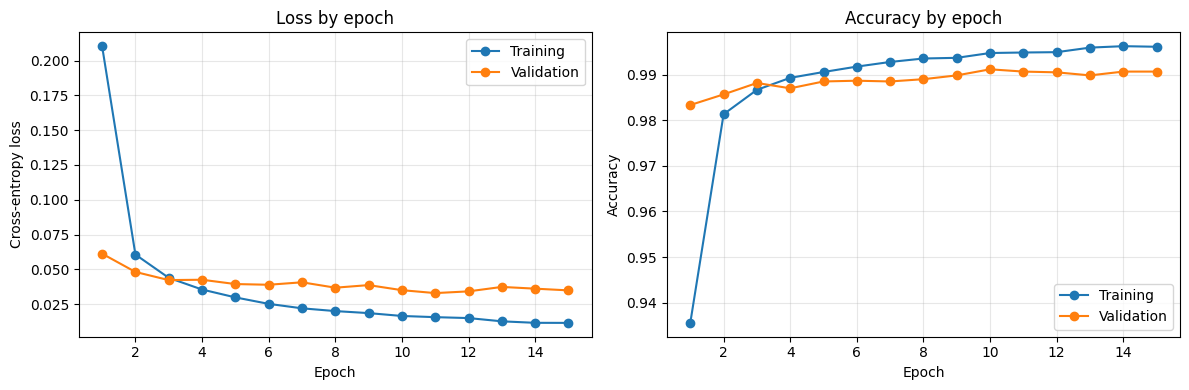

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1) ## Define epochs
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) ## Create figure and subplots 

axes[0].plot(epochs, history["train_loss"], marker="o", label="Training") ## Training Loss graph
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation") ##Validatino Loss graph
axes[0].set_title("Loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Metric results

In [ ]:
## Model metrics and performance for analysis 
model.eval()
all_predictions, all_targets = [], []

with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_predictions.extend(predictions)
        all_targets.extend(y.numpy())

test_accuracy = accuracy_score(all_targets, all_predictions)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    all_targets, all_predictions, average="macro", zero_division=0
)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    all_targets, all_predictions, average="weighted", zero_division=0
)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Macro precision", "Macro recall", "Macro F1",
               "Weighted precision", "Weighted recall", "Weighted F1"],
    "Score": [test_accuracy, precision_macro, recall_macro, f1_macro,
              precision_weighted, recall_weighted, f1_weighted]
})
display(metrics.style.format({"Score": "{:.4f}"}))
print(classification_report(
    all_targets, all_predictions, digits=4, zero_division=0
))


,Metric,Score
0,Accuracy,0.9932
1,Macro precision,0.9931
2,Macro recall,0.9932
3,Macro F1,0.9931
4,Weighted precision,0.9932
5,Weighted recall,0.9932
6,Weighted F1,0.9932


              precision    recall  f1-score   support

           0     0.9969    0.9969    0.9969       980
           1     0.9956    0.9991    0.9974      1135
           2     0.9932    0.9942    0.9937      1032
           3     0.9950    0.9950    0.9950      1010
           4     0.9859    0.9969    0.9914       982
           5     0.9889    0.9944    0.9916       892
           6     0.9979    0.9906    0.9942       958
           7     0.9932    0.9893    0.9912      1028
           8     0.9888    0.9959    0.9923       974
           9     0.9960    0.9792    0.9875      1009

    accuracy                         0.9932     10000
   macro avg     0.9931    0.9932    0.9931     10000
weighted avg     0.9932    0.9932    0.9932     10000



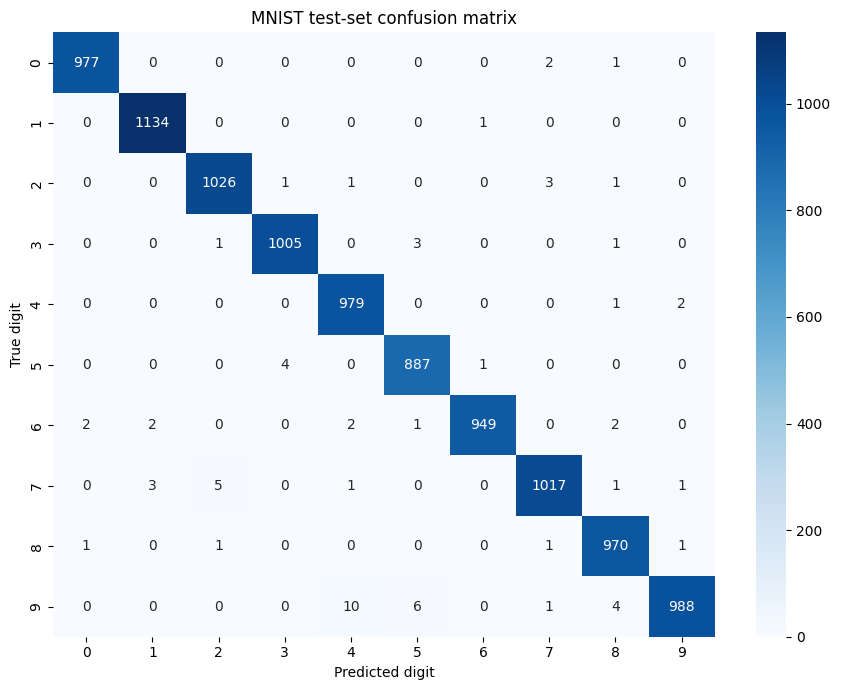

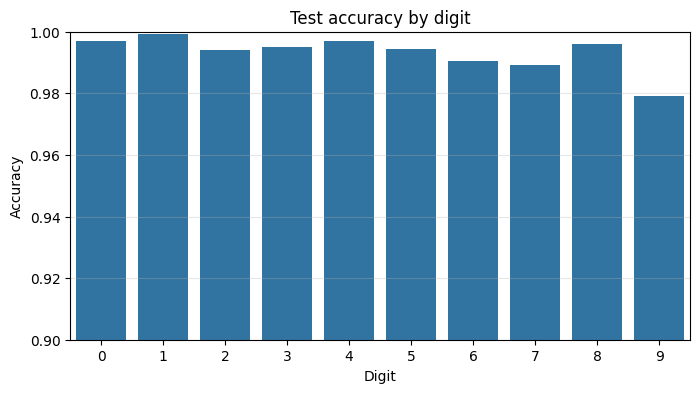

In [ ]:
## Configuration Matrix graph
cm = confusion_matrix(all_targets, all_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("MNIST test-set confusion matrix")
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.tight_layout()
plt.show()

## Digit accuracy graph 
per_class_accuracy = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(8, 4))
sns.barplot(x=np.arange(10), y=per_class_accuracy)
plt.ylim(0.90, 1.0)
plt.title("Test accuracy by digit")
plt.xlabel("Digit")
plt.ylabel("Accuracy")
plt.grid(axis="y", alpha=0.3)
plt.show()


## Incorrect predictions example

Incorrect predictions: 68 / 10000


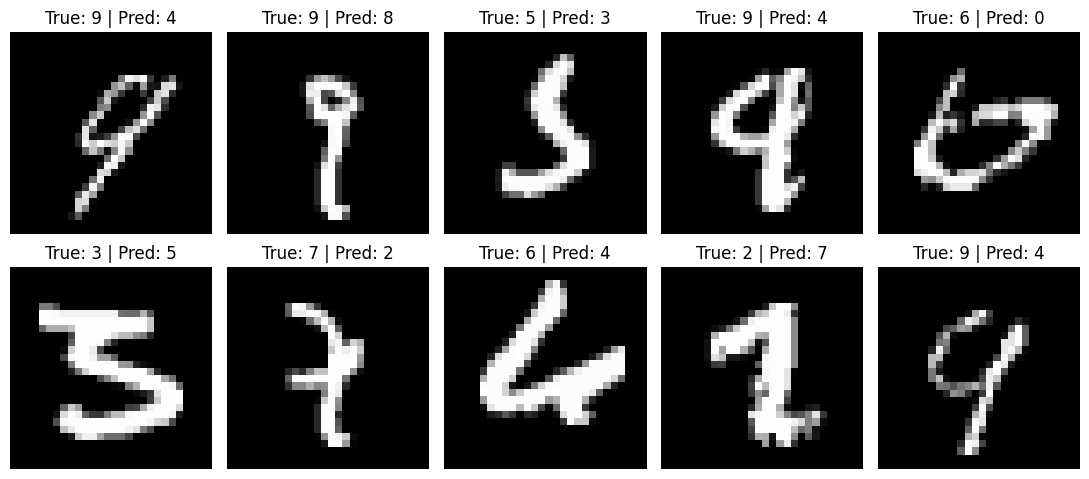

In [ ]:
# Show incorrect predictions for comparison of difficulties
wrong_indices = np.where(np.array(all_predictions) != np.array(all_targets))[0]
print(f"Incorrect predictions: {len(wrong_indices)} / {len(test_dataset)}")

if len(wrong_indices) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(11, 5))
    for ax, idx in zip(axes.flat, wrong_indices[:10]):
        image, true_label = test_dataset[int(idx)]
        shown = image.squeeze().numpy() * 0.3081 + 0.1307
        ax.imshow(shown, cmap="gray")
        ax.set_title(f"True: {true_label} | Pred: {all_predictions[idx]}")
        ax.axis("off")
    for ax in axes.flat[len(wrong_indices[:10]):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## First layer learned features visulaized

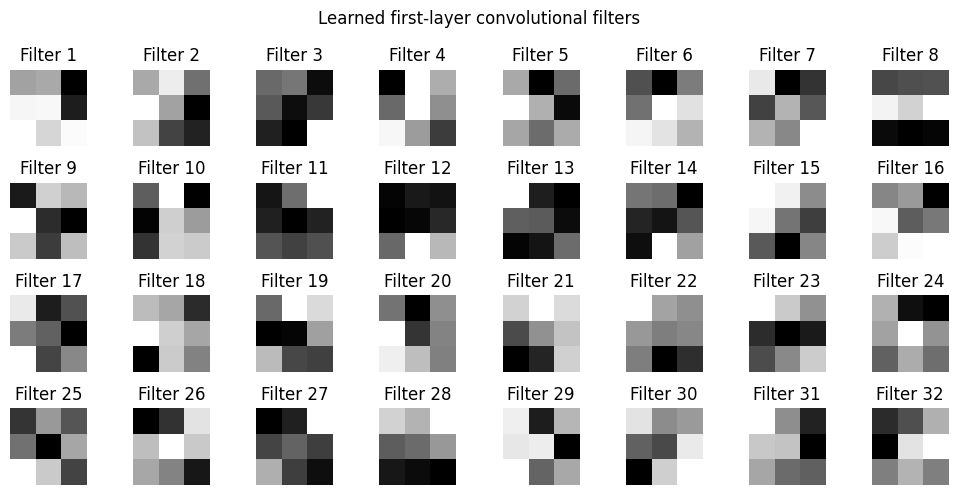

In [9]:
filters = model.conv1.weight.detach().cpu()
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i, 0], cmap="gray")
    ax.set_title(f"Filter {i + 1}")
    ax.axis("off")
plt.suptitle("Learned first-layer convolutional filters")
plt.tight_layout()
plt.show()


## feature maps are visulized

Displayed sample label: 7


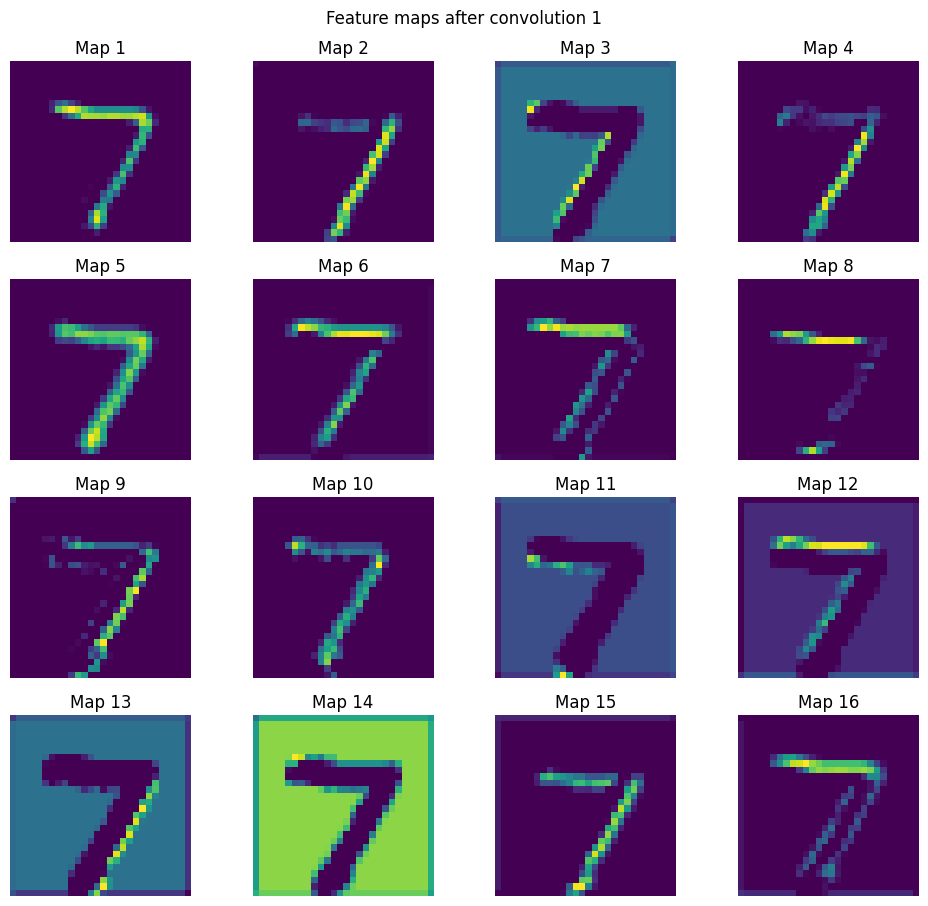

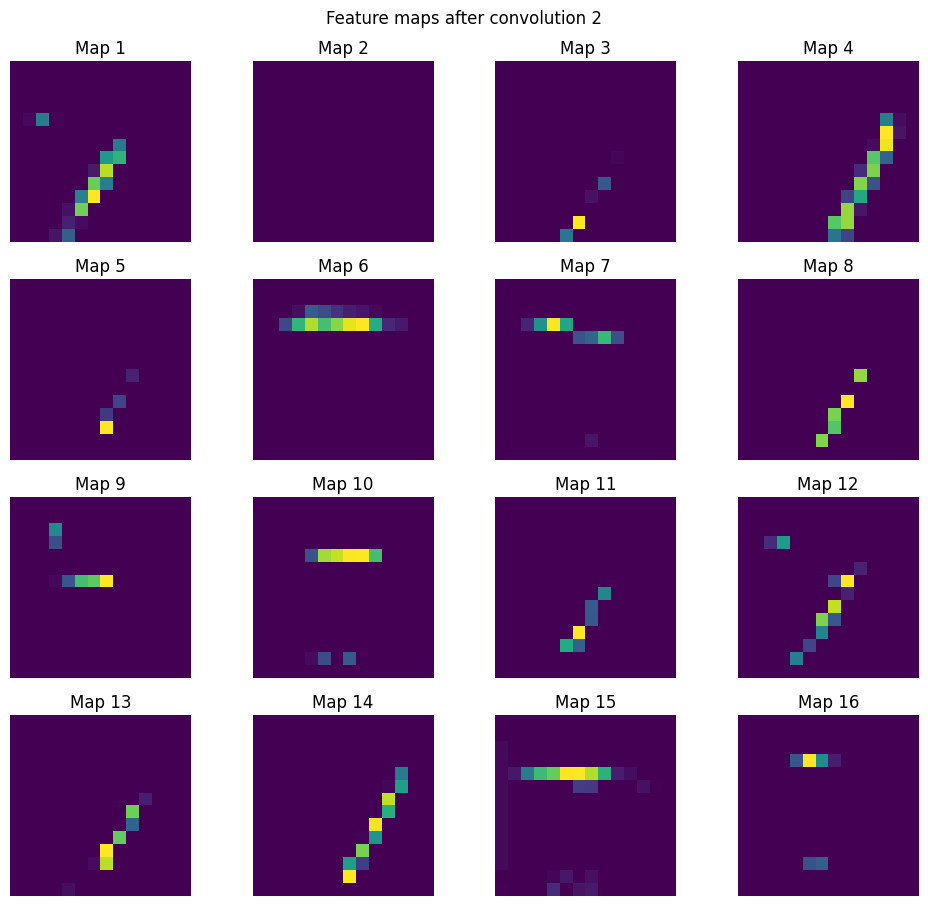

In [ ]:
sample_image, sample_label = test_dataset[0]
model.eval()
with torch.no_grad():
    x = sample_image.unsqueeze(0).to(DEVICE)
    conv1_activations = model.relu1(model.conv1(x))
    pool1_output = model.pool1(conv1_activations)
    conv2_activations = model.relu2(model.conv2(pool1_output))

print("Displayed sample label:", sample_label)

def show_feature_maps(activations, title, max_maps=16):
    maps = activations.squeeze(0).detach().cpu()
    count = min(max_maps, maps.shape[0])
    cols = 4
    rows = int(np.ceil(count / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.3 * rows))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < count:
            ax.imshow(maps[i], cmap="viridis")
            ax.set_title(f"Map {i + 1}")
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_feature_maps(conv1_activations, "Feature maps after convolution 1")
show_feature_maps(conv2_activations, "Feature maps after convolution 2")
